# Transient Stabilitet

I et kraftsystem er endringer vanligvis små og gradvise. Men enkelte hendelser kan forårsake store og plutselige forstyrrelser:

 - plutselige lastendringer
 - inn- og utkobling av linjer eller utstyr
 - bortfall av produksjon
 - kortslutningsfeil

Når slike hendelser oppstår, vil generatorenes rotorvinkler $\delta$, rotasjonshastigheter $\omega$ og den overførte effekten $P_e$ endres raskt.

Ved små forstyrrelser vil generatorene normalt finne en ny stabil driftstilstand. Ved store forstyrrelser kan derimot rotorvinkelen øke så mye at generatoren mister synkronismen med resten av nettet. Generatoren sies da å falle ut av takt (out of step).

Denne typen ustabilitet kalles transient instability (transient ustabilitet).

Transient stabilitet studerer derfor om generatorene klarer å opprettholde synkron drift etter en stor og plutselig forstyrrelse.

## Transient stabilitet

Kortslutninger er blant de mest alvorlige forstyrrelsene i et kraftsystem. Under en feil reduseres den elektriske effekten fra generatorer nær feilstedet kraftig, mens fjerntliggende generatorer påvirkes mindre.

Generatorens dynamikk beskrives av svinge-ligningen:

$$
J\omega\frac{d^2\delta}{dt^2}=P_m-P_e
$$

$$
M\frac{d^2\delta}{dt^2}=P_m-P_e
$$

Under feilen reduseres vanligvis $P_e$, slik at rotoren akselererer og rotorvinkelen $\delta$ øker.

Om systemet forblir stabilt avhenger av:

- feiltype
- feilplassering
- feilvarighet (clearing time)
- metode for feilutkobling

Ved alvorlige feil må feilen kobles ut raskt nok til at

$$
\delta < \delta_{cc}
$$

hvor $\delta_{cc}$ er den kritiske utkoblingsvinkelen.

Transient stabilitetsgrensen er vanligvis lavere enn steady-state stabilitetsgrensen og er derfor ofte den dimensjonerende stabilitetsfaktoren i kraftsystemer.

## Mekanisk bakgrunn for transient stabilitet

Transient stabilitet involverer både elektriske og mekaniske egenskaper ved synkrongeneratorer.

Etter en forstyrrelse må generatorenes rotorer endre sine relative vinkler for å oppnå en ny balanse mellom mekanisk inngangseffekt og elektrisk utgangseffekt.

Systemets oppførsel beskrives av swing-ligningen:

$$
M\frac{d^2\delta}{dt^2}=P_m-P_e
$$

der

- $M$ er rotorens treghetskonstant
- $P_m$ er mekanisk tilført effekt
- $P_e$ er elektrisk avgitt effekt
- $\delta$ er rotorvinkelen

## Kinetisk Energi (KE) og vinkelmoment (M)

Den lagrede kinetiske energien i en synkronmaskin er

$$
\text{K.E.}=\frac{1}{2}J\omega^2
\quad \text{(MJ)}
$$

der

- $J$ er treghetsmomentet i $MJ sek^2/elektriske grader^2$
- $\omega$ er rotasjonshastigheten i $elektriske grader/sek$
- $M=J\omega$ er maskinens vinkelmoment

Siden

$$
M=J\omega
$$

kan den kinetiske energien også skrives som

$$
\text{K.E.}
=
\frac{1}{2}M\omega \quad \text{(MJ)}
$$

## Treghetskonstanten $H$ og vinkelmomentet $M$

Treghetskonstanten $H$ defineres som den lagrede kinetiske energien ved synkron hastighet per MVA merkestørrelse:

$$
H
=
\frac{\text{K.E. ved synkron hastighet}}
{\text{MVA-base}}
\qquad (\text{MJ/MVA})
$$

La G være nominell MVA:

$$
\text{Lagret Energi} = G H [MJ]
$$

Videre ome kinetisk energi:

$$
\text{K.E.}=\frac{1}{2}M\omega^2 \quad \text{[MJ]} = \frac{1}{2}M(2\pi f) \quad \text{[MJ]} = M(2\pi f) \quad \text{[MJ]} 
$$

Fra disse ligningene får vi

$$
GH
=
M \pi f
$$

Når effekt er i pu, er G = 1.0 pu og dermed:

$$
M
=
\frac{H}{\pi f}.
$$





## Treghetskonstanten $H$ versus vinkelmomentet $M$

Vinkelmomentet $M$ avhenger både av maskintype og maskinstørrelse. Store generatorer har derfor vanligvis større $M$ enn små generatorer.

Treghetskonstanten $H$ er derimot den lagrede kinetiske energien per MVA merkestørrelse:

$$
H=\frac{\text{Lagret kinetisk energi}}{\text{MVA-rating}}
$$

Siden $H$ er normalisert med maskinstørrelsen, varierer den relativt lite for samme type maskin.

Dermed:

- $M$ avhenger av maskinens størrelse og type.
- $H$ avhenger hovedsakelig av maskintypen.
- Maskiner innen samme klasse har ofte omtrent samme verdi av $H$.

Dette gjør $H$ til en praktisk parameter i transientstabilitetsanalyser, siden den beskriver maskinens treghet uavhengig av størrelsen.

### Fysisk betydning


- Stor $H$ ⇒ stor lagret rotasjonsenergi.
- Stor $H$ ⇒ rotorhastigheten endres langsommere ved en forstyrrelse.
- Stor $H$ ⇒ bedre transient stabilitet.

Maskiner med høy treghet akselererer derfor saktere når

$$
P_m-P_e > 0,
$$

og gir mer tid til at vern og brytere kan koble ut en feil.


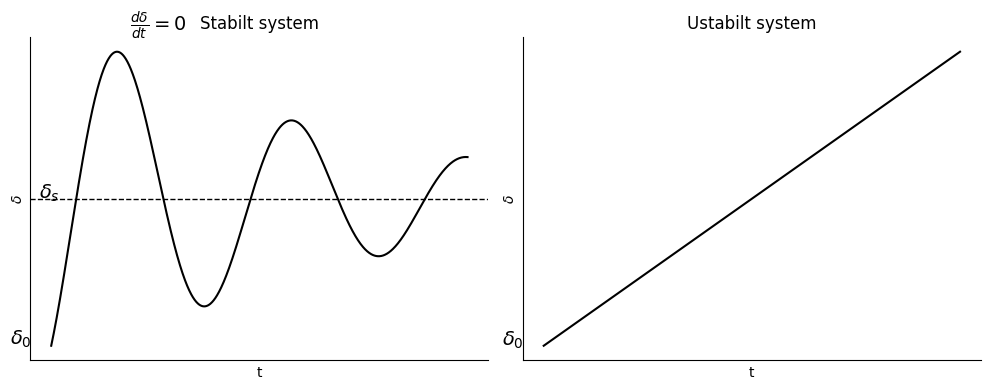

In [5]:
# TEST CELL
import numpy as np
import matplotlib.pyplot as plt

# Tid
t = np.linspace(0, 10, 1000)

# Stabil respons (dempet oscillasjon)
delta_s = 1.0
delta0 = 0.3
delta_stable = delta_s + 0.9*np.exp(-0.15*t)*np.sin(1.5*t - 0.9)

# Ustabil respons
delta_unstable = delta0 + 0.15*t

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Stabil
ax[0].plot(t, delta_stable, 'k')
ax[0].axhline(delta_s, color='k', linestyle='--', linewidth=1)

ax[0].set_xlabel('t')
ax[0].set_ylabel(r'$\delta$')
ax[0].set_title('Stabilt system')

# Marker første topp der dδ/dt = 0
idx = np.argmax(delta_stable[:300])
ax[0].text(t[idx]+0.3,
           delta_stable[idx]+0.1,
           r'$\frac{d\delta}{dt}=0$',
           fontsize=14)

ax[0].text(-0.99, delta0, r'$\delta_0$', fontsize=14)
ax[0].text(-0.3, delta_s, r'$\delta_s$', fontsize=14)

# Ustabil
ax[1].plot(t, delta_unstable, 'k')
ax[1].set_xlabel('t')
ax[1].set_ylabel(r'$\delta$')
ax[1].set_title('Ustabilt system')

ax[1].text(-0.99, delta0, r'$\delta_0$', fontsize=14)

# Felles stil
for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.set_xticks([])
    a.set_yticks([])

plt.tight_layout()
plt.show()

## Svinge-ligningen

Differensialligningen som beskriver sammenhengen mellom rotorvinkelen $\delta$, vinkelmomentet $M$ og akselererende effekt $P_a$ kalles **svinge-ligningen**.

Løsningen av svinge-ligningen viser hvordan rotorvinkelen varierer med tiden etter en forstyrrelse.

Kurven som viser rotorvinkelen som funksjon av tiden,

$$
\delta(t),
$$

kalles **svinge-kurven**.

Ved å studere svinge-kurven kan man avgjøre om kraftsystemet forblir stabilt eller mister synkronismen.

![generator](../images/pm_pe_gen.png)

## Effektbalanse i en generator

En generator mottar mekanisk effekt, $P_m$, fra turbinen via akselmomentet $T_s$.

Generatoren leverer elektrisk effekt, $P_e$ til kraftsystemet.

Samtidig utvikles et elektromagnetisk moment, $T_e$, som virker mot akselmomentet.

Ved stasjonær drift gjelder$T_s=T_e$. Forskjellen mellom disse er akselerasjon $T_a=T_s-T_e$. Multipliserer med $\omega$ på begge sider og får $P_a=P_s-P_e$.

Generelt:

$$P_a = P_{inn} - P_{ut}$$

Relatert til svingeligningen kan vi utrykke Pa som:

$$P_a = T_a \omega = J \alpha \omega = M \alpha = M \frac{d^2 \theta}{dt^2} $$

og dermed

$$
P_m=P_e.
$$

Rotoren roterer da med konstant synkron hastighet.

# Admittansmodellen og sammenhengen med $P_e = P_{\max}\sin\delta$

Admittansmodellen er den generelle nettverksmodellen som brukes før man gjør SMIB-forenklingen. I stedet for å representere nettet med én ekvivalent reaktans, beskrives hele kraftsystemet ved hjelp av admittansmatrisen $Y_{bus}$.

For node $k$ gjelder

$$
I_k=\sum_{i=1}^{n} Y_{ki}V_i
$$

der

- $Y_{ki}=G_{ki}+jB_{ki}$
- $V_i=|V_i|\angle\delta_i$

Den aktive effekten i node $k$ kan skrives som

$$
P_k
=
\sum_{i=1}^{n}
|V_k||V_i||Y_{ki}|
\cos(\theta_{ki}+\delta_i-\delta_k)
$$

der

$$
\theta_{ki}=\angle Y_{ki}.
$$

Dette er den generelle effektligningen basert på admittansmatrisen.

---

## To-port-modell

Etter Kron-reduksjon kan nettet ofte reduseres til to interne generatorspenninger

$$
E'_1\angle\delta_1
$$

og

$$
E'_2\angle\delta_2
$$

koblet sammen gjennom en ekvivalent admittans

$$
Y_{12}=|Y_{12}|\angle\theta_{12}.
$$

Effekten fra maskin 1 blir da

$$
P_1
=
|E'_1||E'_2||Y_{12}|
\cos(\theta_{12}+\delta_2-\delta_1).
$$

Dette kalles ofte admittansmodellen eller to-port-modellen.

---

## Overgang til SMIB-modellen

Anta at forbindelsen mellom maskinene er en ren reaktans

$$
X_{eq}.
$$

Da blir admittansen

$$
Y_{12}
=
\frac{1}{jX_{eq}}
=
-\frac{j}{X_{eq}}.
$$

Dermed får vi

$$
|Y_{12}|=\frac{1}{X_{eq}}
$$

og

$$
\theta_{12}=-90^\circ.
$$

Setter vi dette inn i effektuttrykket:

$$
P_e
=
|E'||V|
\frac{1}{X_{eq}}
\cos(\delta-90^\circ).
$$

Ved å bruke identiteten

$$
\cos(\delta-90^\circ)=\sin\delta
$$

får vi

$$
P_e
=
\frac{|E'||V|}{X_{eq}}
\sin\delta.
$$

---

## Definisjon av maksimal effekt

Den maksimale overførbare effekten defineres som

$$
P_{\max}
=
\frac{|E'||V|}{X_{eq}}.
$$

Dermed fås den klassiske kraftvinkelligningen

$$
P_e=P_{\max}\sin\delta.
$$

---

## Sammenheng mellom modellene

$$
\text{Admittansmodell}
\rightarrow
\text{To-port-modell}
\rightarrow
\text{SMIB}
\rightarrow
P_e=P_{\max}\sin\delta
$$

Uttrykket

$$
P_e=P_{\max}\sin\delta
$$

er altså et spesialtilfelle av den generelle effektligningen når

- nettet er tapsfritt ($G=0$),
- spenningene $|E'|$ og $|V|$ antas konstante,
- nettet kan representeres av én ekvivalent reaktans $X_{eq}$.

# Svingeligning med p_max

$$P_a = T_a \omega = J \alpha \omega = M \alpha = M \frac{d^2 \theta}{dt^2} $$

$$M \frac{d^2 \theta}{dt^2} = P_a$$

$P_a=P_m-P_e$.

$$M \frac{d^2 \theta}{dt^2} = P_m-P_e$$

$$
P_e=P_{\max}\sin\delta
$$

$$M \frac{d^2 \theta}{dt^2} = P_m-P_{\max}\sin\delta$$

# Utledning av Equal Area Criterion

Swing-ligningen for en generator koblet til en infinite bus kan skrives som

$$
M\frac{d^2\delta}{dt^2}
=
\Delta P
=
P_m-P_e.
$$

der

- $M$ = treghetskoeffisient
- $P_m$ = mekanisk effekt
- $P_e$ = elektrisk effekt
- $\Delta P$ = akselerasjonseffekt

Multipliser begge sider med

$$
2\frac{d\delta}{dt}.
$$

Da får vi

$$
2\frac{d\delta}{dt}
\frac{d^2\delta}{dt^2}
=
\frac{2\Delta P}{M}
\frac{d\delta}{dt}.
$$

Ved å bruke kjerneregelen

$$
\frac{d}{dt}
\left(\frac{d\delta}{dt}\right)^2
=
2\frac{d\delta}{dt}
\frac{d^2\delta}{dt^2},
$$

kan ligningen skrives som

$$
\frac{d}{dt}
\left(\frac{d\delta}{dt}\right)^2
=
\frac{2\Delta P}{M}
\frac{d\delta}{dt}.
$$

Bruk nå kjerneregelen

$$
\frac{d}{dt}
=
\frac{d\delta}{dt}
\frac{d}{d\delta}.
$$

Da får vi

$$
d\left(\frac{d\delta}{dt}\right)^2
=
\frac{2\Delta P}{M}\,d\delta.
$$

Integrasjon fra startvinkelen $\delta_0$ til en vilkårlig rotorvinkel $\delta$ gir

$$
\left(\frac{d\delta}{dt}\right)^2
=
\frac{2}{M}
\int_{\delta_0}^{\delta}
\Delta P\,d\delta.
\tag{1}
$$

Siden

$$
\Delta P=P_m-P_e,
$$

kan ligningen skrives som

$$
\left(\frac{d\delta}{dt}\right)^2
=
\frac{2}{M}
\int_{\delta_0}^{\delta}
(P_m-P_e)\,d\delta.
\tag{2}
$$

---

## Stabilitetsbetingelse

For at generatoren skal forbli synkron må rotorvinkelen nå et maksimum og deretter begynne å avta.

Ved maksimal rotorvinkel gjelder

$$
\frac{d\delta}{dt}=0.
$$

Setter vi dette inn i (2), får vi

$$
\int_{\delta_0}^{\delta}
(P_m-P_e)\,d\delta
=
0.
\tag{3}
$$

Dette betyr at nettoarealet mellom kurvene $P_m$ og $P_e$ må være null.

---

## Equal Area Criterion

Akselerasjonsarealet er

$$
A_1
=
\int_{\delta_0}^{\delta_c}
(P_m-P_e)\,d\delta.
$$

Retardasjonsarealet er

$$
A_2
=
\int_{\delta_c}^{\delta_{\max}}
(P_e-P_m)\,d\delta.
$$

Kravet til transient stabilitet er

$$
A_1=A_2.
$$

Dette er kjent som **Equal Area Criterion**.

---

## Fysisk tolkning

- Når $P_m>P_e$, akselererer rotoren og kinetisk energi lagres.
- Når $P_e>P_m$, retarderer rotoren og den lagrede energien fjernes.
- Systemet er stabilt dersom all energien som ble lagret under akselerasjonen fjernes under retardasjonen.

Grafisk betyr dette at akselerasjons- og retardasjonsarealene i $P$-$\delta$-diagrammet må være like store:

$$
A_1=A_2.
$$

# Equal Area Criterion (Likarealkriteriet)

Akselerasjonseffekten i swing-ligningen inneholder et sinusledd. Swing-ligningen blir derfor en ikke-lineær differensialligning, og det er generelt vanskelig å finne en analytisk løsning.

For et system med to maskiner eller en generator koblet til en infinite bus (SMIB), kan transient stabilitet vurderes uten å løse swing-ligningen direkte. Dette gjøres ved hjelp av **Equal Area Criterion (likarealkriteriet)**.

Likarealkriteriet avgjør om systemet er transient stabilt ved å sammenligne arealer i kraftvinkeldiagrammet ($P$-$\delta$-diagrammet). Dersom de nødvendige arealbetingelsene er oppfylt, vil rotorvinkelen forbli begrenset, og systemet er stabilt.

---

## Grunnidé

Swing-ligningen er

$$
M\frac{d^2\delta}{dt^2}=P_m-P_e
$$

der

- $P_m$ = mekanisk tilført effekt
- $P_e$ = elektrisk avgitt effekt
- $\delta$ = rotorvinkel
- $M$ = treghetskonstant

Akselerasjonseffekten er

$$
P_a=P_m-P_e.
$$

- Hvis $P_a>0$, akselererer rotoren og $\delta$ øker.
- Hvis $P_a<0$, bremser rotoren og $\delta$ reduseres.

---

## Stabilitetsbetingelse

Etter en forstyrrelse må rotorvinkelen nå et maksimum og deretter begynne å avta.

Ved maksimumspunktet gjelder

$$
\frac{d\delta}{dt}=0.
$$

Dette betyr at all kinetisk energi som ble lagret under akselerasjonen, er tatt ut igjen under retardasjonen.

I et reelt kraftsystem finnes det alltid en viss demping. Derfor vil de påfølgende oscillasjonene gradvis avta.

Hvis rotorvinkelen når et maksimum der

$$
\frac{d\delta}{dt}=0,
$$

og deretter begynner å bevege seg tilbake, er systemet transient stabilt.

---

## Likarealkriteriet

Under feilen gjelder vanligvis

$$
P_e<P_m,
$$

slik at maskinen akselererer.

Akselerasjonsarealet er

$$
A_1
=
\int_{\delta_0}^{\delta_c}
(P_m-P_e)\,d\delta.
$$

Etter feilutkobling blir vanligvis

$$
P_e>P_m,
$$

slik at maskinen retarderer.

Retardasjonsarealet er

$$
A_2
=
\int_{\delta_c}^{\delta_{\max}}
(P_e-P_m)\,d\delta.
$$

Transient stabilitet krever

$$
A_1=A_2.
$$

Dette er opphavet til navnet **Equal Area Criterion**.

---

## Tolkning

- $A_1$ representerer energi som lagres som kinetisk energi i rotoren under feilen.
- $A_2$ representerer energi som fjernes etter at feilen er koblet ut.
- Dersom

$$
A_2 \ge A_1,
$$

kan rotoren bremses opp og synkronismen beholdes.

- Dersom

$$
A_2 < A_1,
$$

fortsetter rotorvinkelen å øke, og generatoren mister synkronismen.

---

## Oppsummering

Likarealkriteriet gjør det mulig å bestemme transient stabilitet uten å løse swing-ligningen direkte.

For et stabilt system må energien som rotoren får under akselerasjonen være lik energien som fjernes under retardasjonen:

$$
A_1=A_2.
$$

Når denne betingelsen er oppfylt, vil rotorvinkelen nå et maksimum hvor

$$
\frac{d\delta}{dt}=0,
$$

og deretter svinge tilbake mot et nytt stabilt arbeidspunkt.

Fra ligning (20) har vi

$$
\frac{d\delta}{dt}
=
\sqrt{
\int_{\delta_0}^{\delta}
\frac{2(P_m-P_e)}{M}\,d\delta
}.
$$

Rotorvinkelen slutter å endre seg når maskinen igjen går med synkron hastighet, det vil si når

$$
\frac{d\delta}{dt}=0.
$$

For at dette skal være oppfylt, må uttrykket under kvadratroten være null:

$$
\int_{\delta_0}^{\delta}
\frac{2(P_m-P_e)}{M}\,d\delta
=
0.
$$

Siden $M$ er en konstant, kan faktoren $\frac{2}{M}$ trekkes utenfor integralet:

$$
\frac{2}{M}
\int_{\delta_0}^{\delta}
(P_m-P_e)\,d\delta
=
0.
$$

Dermed fås betingelsen

$$
\int_{\delta_0}^{\delta}
(P_m-P_e)\,d\delta
=
0.
\tag{21}
$$

Dette betyr at nettoarealet mellom den mekaniske effekten $P_m$ og den elektriske effekten $P_e$ må være null.

Deler vi integralet inn i et akselerasjonsområde og et retardasjonsområde, får vi

$$
A_1=A_2,
$$

der

$$
A_1
=
\int_{\delta_0}^{\delta_c}
(P_m-P_e)\,d\delta
$$

er akselerasjonsarealet, og

$$
A_2
=
\int_{\delta_c}^{\delta_{\max}}
(P_e-P_m)\,d\delta
$$

er retardasjonsarealet.

Denne betingelsen er kjent som **Equal Area Criterion**.

# Utledning av Equal Area Criterion

Vi ønsker å finne betingelsen for at rotorhastighetsavviket skal bli null, dvs.

$$
\frac{d\delta}{dt}=0.
$$

Swing-ligningen for en generator koblet til en infinite bus er

$$
M\frac{d^2\delta}{dt^2}=P_m-P_e
\tag{18}
$$

der

- $M$ = treghetskoeffisient
- $P_m$ = mekanisk effekt
- $P_e$ = elektrisk effekt

Multipliser begge sider med

$$
\frac{d\delta}{dt}
$$

slik at

$$
M\frac{d^2\delta}{dt^2}\frac{d\delta}{dt}
=
(P_m-P_e)\frac{d\delta}{dt}
$$

Omskriver vi ligningen

$$
M\frac{d\delta}{dt}
\frac{d}{dt}
\left(\frac{d\delta}{dt}\right)=
(P_m-P_e)\frac{d\delta}{dt}
$$

Ved å bruke identiteten

$$
\frac{d}{dt}(x^2)
=
2x\frac{dx}{dt},
$$

med

$$
x=\frac{d\delta}{dt},
$$

får vi

$$
M\frac{d^2\delta}{dt^2}\frac{d\delta}{dt}
=
\frac{M}{2}
\frac{d}{dt}
\left(\frac{d\delta}{dt}\right)^2.
$$

Dermed fås

$$
\frac{M}{2}
\frac{d}{dt}
\left(\frac{d\delta}{dt}\right)^2
=
(P_m-P_e)\frac{d\delta}{dt}
\tag{19}
$$

eller

$$
\frac{d}{dt}
\left(\frac{d\delta}{dt}\right)^2
=
\frac{2(P_m-P_e)}{M}
\frac{d\delta}{dt}.
$$

Ved å bruke kjerneregelen

$$
\frac{d}{dt}
=
\frac{d\delta}{dt}
\frac{d}{d\delta},
$$

får vi

$$
\frac{d}{d\delta}
\left(\frac{d\delta}{dt}\right)^2
=
\frac{2(P_m-P_e)}{M}.
$$

Integrasjon fra startvinkelen $\delta_0$ til en vilkårlig vinkel $\delta$ gir

$$
\left(\frac{d\delta}{dt}\right)^2
=
\int_{\delta_0}^{\delta}
\frac{2(P_m-P_e)}{M}\,d\delta.
$$

Dermed

$$
\frac{d\delta}{dt}
=
\sqrt{
\int_{\delta_0}^{\delta}
\frac{2(P_m-P_e)}{M}\,d\delta
}
\tag{20}
$$

---

## Før forstyrrelsen

Før forstyrrelsen er systemet i stasjonær drift med rotorvinkel

$$
\delta_0.
$$

Da gjelder

$$
P_m=P_e
$$

og

$$
\frac{d\delta}{dt}=0.
$$

Når en forstyrrelse oppstår, blir

$$
P_m \neq P_e,
$$

og rotorvinkelen begynner å endres.

---

## Betingelse for stabilitet

For at rotorvinkelen skal nå et maksimum og deretter vende tilbake, må hastigheten bli null ved et senere tidspunkt:

$$
\frac{d\delta}{dt}=0.
$$

Fra ligning (20) følger det at

$$
\int_{\delta_0}^{\delta}
(P_m-P_e)\,d\delta
=
0.
$$

Det betyr at nettoenergien som rotoren mottar under akselerasjon må være lik energien som avgis under retardasjon.

Grafisk innebærer dette at arealet mellom $P_m$-linjen og $P_e$-kurven må være null.

Dersom integralet deles inn i et akselerasjonsområde og et retardasjonsområde, fås

$$
A_1=A_2.
$$

hvor

$$
A_1
=
\int_{\delta_0}^{\delta_c}
(P_m-P_e)\,d\delta
$$

er akselerasjonsarealet, og

$$
A_2
=
\int_{\delta_c}^{\delta_{\max}}
(P_e-P_m)\,d\delta
$$

er retardasjonsarealet.

Likheten

$$
A_1=A_2
$$

er kjent som **Equal Area Criterion** og utgjør stabilitetsbetingelsen for en generator koblet til en infinite bus.

Ved å multiplisere swing-ligningen med $\dfrac{d\delta}{dt}$ kan venstresiden skrives som

$$
M\frac{d^2\delta}{dt^2}\frac{d\delta}{dt}
=
\frac{M}{2}\frac{d}{dt}\left(\frac{d\delta}{dt}\right)^2.
$$

Uttrykket

$$
\frac{1}{2}M\left(\frac{d\delta}{dt}\right)^2
$$

har samme form som kinetisk energi. Dermed representerer høyresiden den tidsderiverte av rotorens kinetiske energi. Equal Area Criterion er derfor en energibalanse mellom energien som tilføres rotoren under akselerasjon og energien som fjernes under retardasjon.


| Egenskap | Steady-state stability | Transient stability |
|-----------|-----------|-----------|
| Type forstyrrelse | Små og gradvise endringer | Store og plutselige forstyrrelser |
| Eksempler | Gradvis lastøkning | Kortslutninger, generatorutfall, linjeutkobling |
| Analysefokus | Nytt driftspunkt etter små endringer | Rotorens dynamiske respons etter en feil |
| Effektvinkel | Små endringer i $\delta$ | Store utsving i $\delta$ |
| Stabilitetskriterium | $\frac{dP_e}{d\delta} > 0$ | Equal Area Criterion eller swing-ligningen |
| Effektmodell | $P_e = P_{\max}\sin\delta$ | $P_e = P_{\max}\sin\delta$ før, under og etter feil |
| Kritisk grense | $\delta \approx 90^\circ$ | $\delta < \delta_{cc}$ |
| Matematisk verktøy | Statisk analyse | Dynamisk analyse |
| Dominerende ligning | $P_m = P_e$ | $M\frac{d^2\delta}{dt^2}=P_m-P_e$ |
| Tidsskala | Sekunder til minutter | Millisekunder til omtrent 1 s |
| Typisk spørsmål | Hvor mye kan lasten økes før synkronismen mistes? | Hvor lenge kan feilen stå før generatoren mister synkronismen? |